In [1]:
from openfermion.ops import QubitOperator
import numpy as np
from tqdm import tqdm
import pandas as pd
from IPython.display import display, clear_output
import matplotlib.pyplot as plt
import networkx as nx

In [2]:
from qiskit.circuit.library import TwoLocal, RealAmplitudes, EfficientSU2
from qiskit import QuantumCircuit, QuantumRegister
from qiskit.circuit import Parameter
from qiskit_algorithms import NumPyMinimumEigensolver
# from qiskit import execute, Aer
from qiskit.primitives import BackendSampler
from qiskit.primitives import Sampler
from qiskit.providers.options import Options
# from qiskit.providers.aer import AerSimulator
from qiskit_algorithms.optimizers import SLSQP,COBYLA,ADAM, SPSA, QNSPSA,NFT
from qiskit.quantum_info import SparsePauliOp
from qiskit.circuit.library import TwoLocal

In [3]:
from qiskit_algorithms import SamplingVQE

In [4]:
from qiskit_aer import AerSimulator

In [5]:
import matplotlib as mpl
import os

# Set TEX environment variable
# os.environ['TEX'] = '/home/himashu/.TinyTeX'

# Add TinyTeX bin directory to PATH
# os.environ['PATH'] = '/home/himashu/.TinyTeX/bin/x86_64-linux:' + os.environ['PATH']

# Configure matplotlib to use LaTeX
# mpl.rcParams['text.usetex'] = True
# plt.rcParams['font.family'] = 'comfortaa'
plt.rcParams['text.color'] = 'k'
plt.rcParams['axes.labelcolor'] = 'k'
plt.style.use('seaborn-v0_8')
# plt.style.use('default')

In [6]:
adjacency_matrix = np.array([[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
 [0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
 [0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0],
 [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0],
 [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0],
 [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0],
 [0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0],
 [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1],
 [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]],dtype = float)



# adjacency_matrix = np.array([[0,1,0,0,0,0,0,0],
#                              [0,0,1,0,1,0,0,0],
#                              [0,0,0,1,0,0,0,0],
#                              [0,0,0,0,1,0,1,0],
#                              [0,0,0,0,0,1,0,0],
#                              [0,0,1,0,0,0,1,0],
#                              [0,0,0,0,0,0,0,1],
#                              [0,0,0,0,0,0,0,0]
#                              ],dtype = float)


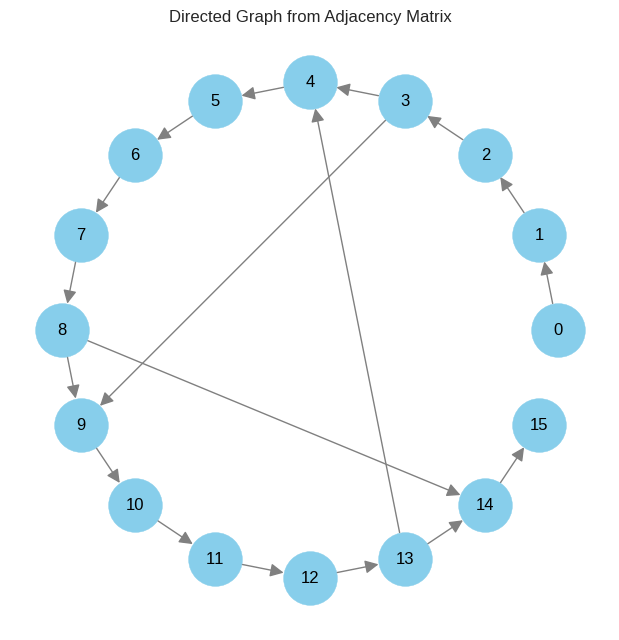

In [7]:
# Create a directed graph from the adjacency matrix
G = nx.from_numpy_array(adjacency_matrix, create_using=nx.DiGraph)

# Draw the graph
plt.figure(figsize=(6, 6))
pos = nx.circular_layout(G)  # positions for all nodes
nx.draw(G, pos, with_labels=True, node_color='skyblue', node_size=1500, edge_color='gray', arrowsize=20)
plt.title('Directed Graph from Adjacency Matrix')
# plt.savefig('graph.jpg')
plt.show()

In [8]:
W = -2*np.array(adjacency_matrix,dtype = float)

# W = np.random.randint(low = 20,high = 30,size = (W.shape[0],W.shape[1]))*W 

# W1 = np.copy(W)
# W1 = W1

num_pos = W.shape[0] # int(1.2*len(read))
# A = np.zeros_like(W,dtype = int)

α = 10.0*np.max(abs(W))

for i in range(len(W)):
    for j in range(len(W)):
        if W[i,j] == 0:
            W[i,j] = α # + np.random.uniform()


node = W.shape[0]
node_qubit = int(np.ceil(np.log2(node)))
num_qubits = node_qubit*num_pos
print('Number of qubits for nodes :', node_qubit)
print('Number of positions : ',num_pos)
print('Number of qubits required:', num_qubits)

print(pd.DataFrame(W))


Number of qubits for nodes : 4
Number of positions :  16
Number of qubits required: 64
      0     1     2     3     4     5     6     7     8     9     10    11  \
0   20.0  -2.0  20.0  20.0  20.0  20.0  20.0  20.0  20.0  20.0  20.0  20.0   
1   20.0  20.0  -2.0  20.0  20.0  20.0  20.0  20.0  20.0  20.0  20.0  20.0   
2   20.0  20.0  20.0  -2.0  20.0  20.0  20.0  20.0  20.0  20.0  20.0  20.0   
3   20.0  20.0  20.0  20.0  -2.0  20.0  20.0  20.0  20.0  -2.0  20.0  20.0   
4   20.0  20.0  20.0  20.0  20.0  -2.0  20.0  20.0  20.0  20.0  20.0  20.0   
5   20.0  20.0  20.0  20.0  20.0  20.0  -2.0  20.0  20.0  20.0  20.0  20.0   
6   20.0  20.0  20.0  20.0  20.0  20.0  20.0  -2.0  20.0  20.0  20.0  20.0   
7   20.0  20.0  20.0  20.0  20.0  20.0  20.0  20.0  -2.0  20.0  20.0  20.0   
8   20.0  20.0  20.0  20.0  20.0  20.0  20.0  20.0  20.0  -2.0  20.0  20.0   
9   20.0  20.0  20.0  20.0  20.0  20.0  20.0  20.0  20.0  20.0  -2.0  20.0   
10  20.0  20.0  20.0  20.0  20.0  20.0  20.0  20.0  20.

In [9]:
def P0(i):
    iden = QubitOperator('')
    Z = QubitOperator('Z' + str(i))
    return 0.5*(iden + Z)


def P1(i):
    iden = QubitOperator('')
    Z = QubitOperator('Z' + str(i))
    return 0.5*(iden - Z)


def number_to_fixed_length_binary_array(number, length):
    binary_string = bin(number)[2:]  # Get binary representation as a string, removing the '0b' prefix
    padded_binary_string = binary_string.zfill(length)  # Pad with leading zeros to ensure fixed length
    binary_array = np.array([int(bit) for bit in padded_binary_string])  # Convert binary string to numpy array
    return binary_array

def occupation_op(num,pos,N):
    
    # num : node number 
    # N : total qubit for node
    # pos : position runs from 0 to edge - 1

    Ait = QubitOperator('')
    
    binary_array = number_to_fixed_length_binary_array(num, N)
    Nbit = len(binary_array)
    for i in range(Nbit):
        if binary_array[i] == 1:
            Ait = Ait*P1(i + pos*Nbit)
        else:
            Ait = Ait*P0(i + pos*Nbit)
   
    return Ait 


bit = []

for ti in (range(num_pos)):
    bi = []
    for i in range(node):
        bi.append(occupation_op(i,ti,node_qubit))
    bit.append(bi)


In [10]:
# Visit Once 

identity = QubitOperator('')

H1 = 0 

A2 = 1.5*np.max(W)

for i in range(node):
    term = 0
    for t in range(num_pos):
        term += bit[t][i]
    term_sq = (identity-term)*(identity-term)
    H1 += term_sq

# Visit once version 02

# H1 = 0 

# for t in range(num_pos):
#     for tdash in range(t+1,num_pos):
#         for i in range(node):
#             H1 += 2*bit[t][i]*bit[tdash][i] - (1/(node-1))*(bit[t][i] + bit[tdash][i] + 2)


# including weights 

H2 = 0

for t in tqdm(range(num_pos - 1)):
    for i in range(node):
        for j in range(node):
            H2 += W[i,j]*(bit[t][i]*bit[t+1][j])

B = 1

H = A2*H1 + B*H2

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 15/15 [00:07<00:00,  2.05it/s]


In [11]:
H_op = H.terms

print('Constructing Hamiltonian...Completed.')

print('Initiating VQE..')

op = []

for key, value in H_op.items():
    strlist = ['I' for i in range(num_qubits)]  
    for item in key:
        strlist[item[0]] = 'Z'
    op_string = ''.join(strlist)
    op.append((op_string,value))

# op.pop(0)

print(pd.DataFrame(op))

Hop = SparsePauliOp.from_list(op)

Constructing Hamiltonian...Completed.
Initiating VQE..
                                                      0           1
0     IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII...  726.796875
1     IIIZIIIZIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII...    4.953125
2     IIIZIIIIIIIZIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII...    3.750000
3     IIIZIIIIIIIIIIIZIIIIIIIIIIIIIIIIIIIIIIIIIIIIII...    3.750000
4     IIIZIIIIIIIIIIIIIIIZIIIIIIIIIIIIIIIIIIIIIIIIII...    3.750000
...                                                 ...         ...
4276  IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII...   -0.171875
4277  IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII...   -0.171875
4278  IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII...   -0.171875
4279  IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII...    0.171875
4280  IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII...   -0.171875

[4281 rows x 2 columns]


In [12]:
## search for source node : 

for i in range(adjacency_matrix.shape[0]):
    x = np.sum(adjacency_matrix[:,i])
    if x == 0:
        print('source point -- ', i)
        source_node = i
        break


source point --  0


In [13]:
## end node :

for i in range(adjacency_matrix.shape[0]):
    x = np.sum(adjacency_matrix[i,:])
    if x == 0:
        print('end point -- ', i)
        end_node = i
        break


end point --  15


In [14]:
print('source node : ', source_node,' & end node : ', end_node)

source node :  0  & end node :  15


In [15]:
ref = QuantumCircuit(num_qubits)

source_bit = number_to_fixed_length_binary_array(source_node,node_qubit)
end_bit = number_to_fixed_length_binary_array(end_node,node_qubit)

for i in range(node_qubit):
    if source_bit[i] == 1:
        ref.x(num_qubits-1-i) 
    if end_bit[i] == 1:
        ref.x(i)

ref.draw()

┌───┐
 q_0: ┤ X ├
      ├───┤
 q_1: ┤ X ├
      ├───┤
 q_2: ┤ X ├
      ├───┤
 q_3: ┤ X ├
      └───┘
 q_4: ─────
           
 q_5: ─────
           
 q_6: ─────
           
 q_7: ─────
           
 q_8: ─────
           
 q_9: ─────
           
q_10: ─────
           
q_11: ─────
           
q_12: ─────
           
q_13: ─────
           
q_14: ─────
           
q_15: ─────
           
q_16: ─────
           
q_17: ─────
           
q_18: ─────
           
q_19: ─────
           
q_20: ─────
           
q_21: ─────
           
q_22: ─────
           
q_23: ─────
           
q_24: ─────
           
q_25: ─────
           
q_26: ─────
           
q_27: ─────
           
q_28: ─────
           
q_29: ─────
           
q_30: ─────
           
q_31: ─────
           
q_32: ─────
           
q_33: ─────
           
q_34: ─────
           
q_35: ─────
           
q_36: ─────
           
q_37: ─────
           
q_38: ─────
           
q_39: ─────
           
q_40: ─────
           
q_41: ─────
           
q_42: ─────
           
q_43: ─────
           
q_44: ─────
           
q_45: ─────
           
q_46: ─────
           
q_47: ─────
           
q_48: ─────
           
q_49: ─────
           
q_50: ─────
           
q_51: ─────
           
q_52: ─────
           
q_53: ─────
           
q_54: ─────
           
q_55: ─────
           
q_56: ─────
           
q_57: ─────
           
q_58: ─────
           
q_59: ─────
           
q_60: ─────
           
q_61: ─────
           
q_62: ─────
           
q_63: ─────

In [16]:
ansatz = QuantumCircuit(num_qubits)

for i in range(num_pos-2):
    ansatz.append(EfficientSU2(node_qubit,su2_gates=["rx", "ry"], reps=1, parameter_prefix='φ' + str(i) , insert_barriers=True).decompose(), range(node_qubit + i*node_qubit,node_qubit + (i+1)*node_qubit))

ansatz = ref.compose(ansatz)

ansatz.decompose().draw()

┌───────────┐                                                   »
 q_0: ┤ U3(π,0,π) ├───────────────────────────────────────────────────»
      ├───────────┤                                                   »
 q_1: ┤ U3(π,0,π) ├───────────────────────────────────────────────────»
      ├───────────┤                                                   »
 q_2: ┤ U3(π,0,π) ├───────────────────────────────────────────────────»
      ├───────────┤                                                   »
 q_3: ┤ U3(π,0,π) ├───────────────────────────────────────────────────»
      ├───────────┤ ┌───────────┐  ░                 ░  ┌───────────┐ »
 q_4: ┤ Rx(φ0[0]) ├─┤ Ry(φ0[4]) ├──░─────────────■───░──┤ Rx(φ0[8]) ├─»
      ├───────────┤ ├───────────┤  ░           ┌─┴─┐ ░  ├───────────┤ »
 q_5: ┤ Rx(φ0[1]) ├─┤ Ry(φ0[5]) ├──░────────■──┤ X ├─░──┤ Rx(φ0[9]) ├─»
      ├───────────┤ ├───────────┤  ░      ┌─┴─┐└───┘ ░  ├───────────┴┐»
 q_6: ┤ Rx(φ0[2]) ├─┤ Ry(φ0[6]) ├──░───■──┤ X ├──────░──┤ Rx(φ0[10]) ├»
      ├───────────┤ ├───────────┤  ░ ┌─┴─┐└───┘      ░  ├────────────┤»
 q_7: ┤ Rx(φ0[3]) ├─┤ Ry(φ0[7]) ├──░─┤ X ├───────────░──┤ Rx(φ0[11]) ├»
      ├───────────┤ ├───────────┤  ░ └───┘           ░  ├───────────┬┘»
 q_8: ┤ Rx(φ1[0]) ├─┤ Ry(φ1[4]) ├──░─────────────■───░──┤ Rx(φ1[8]) ├─»
      ├───────────┤ ├───────────┤  ░           ┌─┴─┐ ░  ├───────────┤ »
 q_9: ┤ Rx(φ1[1]) ├─┤ Ry(φ1[5]) ├──░────────■──┤ X ├─░──┤ Rx(φ1[9]) ├─»
      ├───────────┤ ├───────────┤  ░      ┌─┴─┐└───┘ ░  ├───────────┴┐»
q_10: ┤ Rx(φ1[2]) ├─┤ Ry(φ1[6]) ├──░───■──┤ X ├──────░──┤ Rx(φ1[10]) ├»
      ├───────────┤ ├───────────┤  ░ ┌─┴─┐└───┘      ░  ├────────────┤»
q_11: ┤ Rx(φ1[3]) ├─┤ Ry(φ1[7]) ├──░─┤ X ├───────────░──┤ Rx(φ1[11]) ├»
      ├───────────┤ ├───────────┤  ░ └───┘           ░  ├───────────┬┘»
q_12: ┤ Rx(φ2[0]) ├─┤ Ry(φ2[4]) ├──░─────────────■───░──┤ Rx(φ2[8]) ├─»
      ├───────────┤ ├───────────┤  ░           ┌─┴─┐ ░  ├───────────┤ »
q_13: ┤ Rx(φ2[1]) ├─┤ Ry(φ2[5]) ├──░────────■──┤ X ├─░──┤ Rx(φ2[9]) ├─»
      ├───────────┤ ├───────────┤  ░      ┌─┴─┐└───┘ ░  ├───────────┴┐»
q_14: ┤ Rx(φ2[2]) ├─┤ Ry(φ2[6]) ├──░───■──┤ X ├──────░──┤ Rx(φ2[10]) ├»
      ├───────────┤ ├───────────┤  ░ ┌─┴─┐└───┘      ░  ├────────────┤»
q_15: ┤ Rx(φ2[3]) ├─┤ Ry(φ2[7]) ├──░─┤ X ├───────────░──┤ Rx(φ2[11]) ├»
      ├───────────┤ ├───────────┤  ░ └───┘           ░  ├───────────┬┘»
q_16: ┤ Rx(φ3[0]) ├─┤ Ry(φ3[4]) ├──░─────────────■───░──┤ Rx(φ3[8]) ├─»
      ├───────────┤ ├───────────┤  ░           ┌─┴─┐ ░  ├───────────┤ »
q_17: ┤ Rx(φ3[1]) ├─┤ Ry(φ3[5]) ├──░────────■──┤ X ├─░──┤ Rx(φ3[9]) ├─»
      ├───────────┤ ├───────────┤  ░      ┌─┴─┐└───┘ ░  ├───────────┴┐»
q_18: ┤ Rx(φ3[2]) ├─┤ Ry(φ3[6]) ├──░───■──┤ X ├──────░──┤ Rx(φ3[10]) ├»
      ├───────────┤ ├───────────┤  ░ ┌─┴─┐└───┘      ░  ├────────────┤»
q_19: ┤ Rx(φ3[3]) ├─┤ Ry(φ3[7]) ├──░─┤ X ├───────────░──┤ Rx(φ3[11]) ├»
      ├───────────┤ ├───────────┤  ░ └───┘           ░  ├───────────┬┘»
q_20: ┤ Rx(φ4[0]) ├─┤ Ry(φ4[4]) ├──░─────────────■───░──┤ Rx(φ4[8]) ├─»
      ├───────────┤ ├───────────┤  ░           ┌─┴─┐ ░  ├───────────┤ »
q_21: ┤ Rx(φ4[1]) ├─┤ Ry(φ4[5]) ├──░────────■──┤ X ├─░──┤ Rx(φ4[9]) ├─»
      ├───────────┤ ├───────────┤  ░      ┌─┴─┐└───┘ ░  ├───────────┴┐»
q_22: ┤ Rx(φ4[2]) ├─┤ Ry(φ4[6]) ├──░───■──┤ X ├──────░──┤ Rx(φ4[10]) ├»
      ├───────────┤ ├───────────┤  ░ ┌─┴─┐└───┘      ░  ├────────────┤»
q_23: ┤ Rx(φ4[3]) ├─┤ Ry(φ4[7]) ├──░─┤ X ├───────────░──┤ Rx(φ4[11]) ├»
      ├───────────┤ ├───────────┤  ░ └───┘           ░  ├───────────┬┘»
q_24: ┤ Rx(φ5[0]) ├─┤ Ry(φ5[4]) ├──░─────────────■───░──┤ Rx(φ5[8]) ├─»
      ├───────────┤ ├───────────┤  ░           ┌─┴─┐ ░  ├───────────┤ »
q_25: ┤ Rx(φ5[1]) ├─┤ Ry(φ5[5]) ├──░────────■──┤ X ├─░──┤ Rx(φ5[9]) ├─»
      ├───────────┤ ├───────────┤  ░      ┌─┴─┐└───┘ ░  ├───────────┴┐»
q_26: ┤ Rx(φ5[2]) ├─┤ Ry(φ5[6]) ├──░───■──┤ X ├──────░──┤ Rx(φ5[10]) ├»
      ├───────────┤ ├───────────┤  ░ ┌─┴─┐└───┘      ░  ├────────────┤»
q_27: ┤ Rx(φ5[3]) ├─┤ Ry(φ5[7]) ├──░─┤ X ├────

In [17]:
# ansatz = QuantumCircuit(num_qubits)

# # Create a list of parameters for the rotations
# ry_params = [Parameter(f'θ_y_{i}') for i in range(Nbit,num_qubits-Nbit)]
# rz_params = [Parameter(f'θ_z_{i}') for i in range(Nbit,num_qubits-Nbit)]

# x = 0
# # Apply R_y and R_z rotations to each qubit
# for i in range(Nbit,num_qubits-Nbit):
#     ansatz.ry(ry_params[x], i)
#     ansatz.rz(rz_params[x], i)
#     x+=1

# # ansatz = EfficientSU2(num_qubits=num_qubits- 2*Nbit,su2_gates=["rx", "ry"],reps=1)

# ansatz = ref.compose(ansatz)

# # ansatz.draw()

In [18]:
ansatz.num_qubits, Hop.num_qubits

(64, 64)

In [1]:
#Hop = SparsePauliOp.from_list(op)


# ## Optimizer : SPSA
# # backend = Aer.get_backend('qasm_simulator')
# # backend = AerSimulator(method = 'matrix_product_state')
# backend = AerSimulator(method = 'matrix_product_state')

# # backend = QasmSimulator(method='matrix_product_state')
# options = Options()
# options.shots = int(2**12) # 4000
# sampler = BackendSampler(backend=backend)

# # set classical optimizer
# #optimizer = SPSA(maxiter = 1000)
# # optimizer = NFT(maxiter=100) # SPSA()
# # optimizer = NFT(maxiter=1000) # SPSA()

# # optimizer = SPSA(
# #     maxiter=1000,
# #     blocking=True,
# #     allowed_increase=0.01,
# #     # trust_region=True,
# #     # learning_rate=lambda k: 0.1 / (k + 1)**0.6,
# #     # perturbation=lambda k: 0.1 / (k + 1)**0.101,
# #     # last_avg=10,
# #     # resamplings=5,
# #     perturbation_dims=None,  # Perturb all dimensions
# #     # second_order=True,
# #     # regularization=lambda x: 0.01 * sum(x**2),  # Example regularization term
# #     # hessian_delay=5,
# #     lse_solver=None,  # Default least-squares solver
# #     initial_hessian=None,  # No initial Hessian
# #     # callback=lambda n, x, fx: print(f"Iteration {n}, x={x}, f(x)={fx}")
# # )

# counts = []
# values = []
# params = []

# # Function to plot energy after each iteration
# def plot_energy(counts, values):
#     fig, ax = plt.subplots(figsize = (6,4))
#     ax.plot(counts, values, marker='o', linestyle='-',color = '#C06C84',markerfacecolor='#355C7D',markersize = 5)
#     plt.tick_params(top=True, left=True, right=True, bottom=True,direction="in",axis='both', which='both', labelsize=15)
#     font2 = {'family':'comfortaa','color':'black','size':18}
#     ax.set_xlabel('Iteration',fontdict = font2)
#     ax.set_ylabel('Energy',fontdict = font2)
#     # plt.title('Energy vs Iteration')
#     ax.grid(zorder=0)
#     plt.show()


# def store_intermediate_result(eval_count, parameters, mean, std):
#     counts.append(eval_count)
#     values.append(np.real(mean))
#     # print(eval_count, "energy_exp = ", np.real(mean))
#     params.append(parameters)
#     # Plot energy after each iteration
#     clear_output(wait=True)
#     plot_energy(counts, values)

# # initialize VQE using CVaR with alpha = 0.1

# vqe = SamplingVQE(
#     sampler,
#     ansatz=ansatz,
#     optimizer=optimizer,
# #     aggregation=0.1,
# #     initial_point = params,
#     callback=store_intermediate_result,
#     )

# # Estimator approach

# # vqe = VQE(
# #     sampler,
# #     ansatz=ansatz,
# #     optimizer=optimizer,
# # #     aggregation=0.1,
# # #     initial_point = params,
# #     callback=store_intermediate_result,
# #     )

# raw_result = vqe.compute_minimum_eigenvalue(Hop) 
# print(raw_result.best_measurement['bitstring'])

# # np.savetxt('energy.txt',np.array(values))

# val = raw_result.best_measurement['bitstring']


In [21]:
#np.set_printoptions(threshold=sys.maxsize)

import pickle
Hop = SparsePauliOp.from_list(op)


import time
from qiskit.circuit.library import RealAmplitudes, EfficientSU2
from qiskit_algorithms.optimizers import COBYLA
from qiskit_algorithms import NumPyMinimumEigensolver
from qiskit_algorithms.minimum_eigensolvers import SamplingVQE
#from qiskit_aer.primitives import Sampler, Estimator
from qiskit_ibm_runtime import SamplerV2 as Sampler
from qiskit_aer import AerSimulator
from scipy.optimize import minimize
from qiskit.result import sampled_expectation_value

cost_history_dict = {
    "prev_vector": None,
    "iters": 0,
    "cost_history": [],
    "job_counts": [],
}

#ansatz = EfficientSU2(num_qubits= op.num_qubits, reps=1)
ansatz.measure_all()

params = np.random.random(ansatz.num_parameters)

def cost_func(params, ansatz, hamiltonian, simul):
    """Return estimate of energy from estimator

    Parameters:
        params (ndarray): Array of ansatz parameters
        ansatz (QuantumCircuit): Parameterized ansatz circuit
        hamiltonian (SparsePauliOp): Operator representation of Hamiltonian
        estimator (EstimatorV2): Estimator primitive instance
        cost_history_dict: Dictionary for storing intermediate results

    Returns:
        float: Energy estimate
    """
    #pub = (ansatz, [hamiltonian], [params])
    #result = estimator.run(pubs=[pub]).result()
    pub = (ansatz, [params])
    job = simul.run(circuits=ansatz.assign_parameters(params),shots=4096)
    result = job.result()
    #print(result)
    #print(result['PrimitiveResult'])#['data'].meas.get_counts())
    #print(result[0].data)
    #print(result)
    samp_counts = result.get_counts() #['__value__']['data'].meas.get_counts() #[0].data.meas.get_counts()
    energy = sampled_expectation_value(samp_counts, hamiltonian)
    #energy = result[0].data.evs[0]

    cost_history_dict["iters"] += 1
    cost_history_dict["prev_vector"] = params
    cost_history_dict["cost_history"].append(energy)
    cost_history_dict["job_counts"].append(list(samp_counts.keys()))
    print(f"Iters. done: {cost_history_dict['iters']} [Current cost: {energy}]")

    return energy

#sampler=Sampler(backend=AerSimulator(method="matrix_product_state"))
simul = AerSimulator(method="matrix_product_state")
#sampler.options.twirling.enable_gates = True
#sampler.options.twirling.enable_measure = False

res = minimize(
    fun=cost_func,
    x0=params,
    #args=(qc, Hop, estimator),
    args=(ansatz.decompose(), Hop, simul),
    method="COBYLA",options={"maxiter":5000}
)


# with open('allBitStrings.pkl', 'wb') as f:
#     pickle.dump(cost_history_dict["job_counts"], f)

Iters. done: 1 [Current cost: 1237.89794921875]
Iters. done: 2 [Current cost: 1185.07470703125]
Iters. done: 3 [Current cost: 1171.94970703125]
Iters. done: 4 [Current cost: 1154.9609375]
Iters. done: 5 [Current cost: 1156.1884765625]
Iters. done: 6 [Current cost: 1162.1572265625]
Iters. done: 7 [Current cost: 1164.57958984375]
Iters. done: 8 [Current cost: 1155.9814453125]
Iters. done: 9 [Current cost: 1154.93408203125]
Iters. done: 10 [Current cost: 1176.359375]
Iters. done: 11 [Current cost: 1163.0634765625]
Iters. done: 12 [Current cost: 1142.64013671875]
Iters. done: 13 [Current cost: 1149.0439453125]
Iters. done: 14 [Current cost: 1154.8857421875]
Iters. done: 15 [Current cost: 1159.193359375]
Iters. done: 16 [Current cost: 1154.4404296875]
Iters. done: 17 [Current cost: 1163.0263671875]
Iters. done: 18 [Current cost: 1113.98388671875]
Iters. done: 19 [Current cost: 1080.0390625]
Iters. done: 20 [Current cost: 1072.36328125]
Iters. done: 21 [Current cost: 1074.30810546875]
Iters.

In [27]:
# np.savetxt('energy_8nodes.txt',np.array(values))


In [31]:
# np.savetxt('parameter_8nodes.txt',np.array(list(raw_result.optimal_parameters.values())))

In [22]:
allBits = []
for i in (cost_history_dict['job_counts']):
    for j in i:
        allBits.append(j)

In [26]:
def violations(val):
    # vio = 0 # number of misalighments
    # num_seq = [] # sequence associated with quantum bit (val)

    # for i in range(num_pos):
    #     num_seq.append(int(val[i*node_qubit:node_qubit*i+node_qubit],2))

    # for i in range(num_pos-1):
    #     if W[num_seq[i]-1,num_seq[i+1]-1] >= 0 and num_seq[i] > 0 and num_seq[i+1] > 0:
    #         vio +=1

    # return vio,num_seq
    
    vio = 0
    num_seq = []

    for i in range(num_pos):
        num_seq.append(int(val[i*node_qubit:node_qubit*i+node_qubit],2))

    for i in range(num_pos-1):
        if adjacency_matrix[num_seq[i],num_seq[i+1]] == 0:
            vio +=1

    return vio,num_seq

objVio = []
allBitS = []
possible_soln = []
for b in allBits:
    #b = service.job(j).result()[0]['__value__']['data'].meas.get_counts()
    #b = list(b.keys())
    #for i in range(len(b)):
    objvio, numseq = violations(b)
    objVio.append(objvio)
    if objvio <= 7: # reduce the cutoff!!
        print(objvio)
        print(numseq)
        print('\n')
        possible_soln.append(b)

#print(raw_result.best_measurement['bitstring'])

# np.savetxt('energy.txt',np.array(values))

#val = raw_result.best_measurement['bitstring']

7
[0, 8, 9, 3, 9, 10, 9, 10, 11, 7, 4, 5, 6, 7, 11, 15]


6
[0, 13, 10, 7, 8, 9, 10, 11, 12, 13, 14, 13, 14, 15, 10, 15]


7
[0, 8, 9, 9, 4, 5, 6, 10, 2, 3, 4, 5, 5, 6, 14, 15]


7
[0, 1, 6, 7, 8, 5, 9, 10, 13, 4, 5, 13, 9, 10, 11, 15]


7
[0, 2, 3, 4, 5, 6, 7, 11, 8, 14, 5, 13, 4, 9, 14, 15]




In [27]:
possible_soln

['0000100010010011100110101001101010110111010001010110011110111111',
 '0000110110100111100010011010101111001101111011011110111110101111',
 '0000100010011001010001010110101000100011010001010101011011101111',
 '0000000101100111100001011001101011010100010111011001101010111111',
 '0000001000110100010101100111101110001110010111010100100111101111']